# GELAR RASA — EDA visual, preprocessing, crop, dan kemiripan piksel

Analisis **1.920 train dan 480 test**, dengan penekanan pada contoh gambar test, kualitas gambar, kandidat beberapa objek, serta hubungan test–train pada tingkat piksel dan ukuran native.

**Asal nama tampilan:** atas permintaan pengguna, asisten meninjau 128 contoh hasil model dan memberi interpretasi visual sementara pada tingkat kelompok. Ini EDA pribadi, bukan label resmi atau pemetaan kategori yang disahkan untuk kompetisi. Aturan yang diberikan pengguna melarang LLM/VLM untuk klasifikasi kompetisi; interpretasi ini dipisahkan dari target training, validasi, dan submission. Tidak ada panggilan LLM/VLM/API inference dalam notebook.

Delapan kelompok model belum terpisah sempurna menjadi delapan material. Kelompok campuran ditulis **plastic / glass** dan **plastic / textile / paper**, sehingga gambar kaca tidak dianggap tidak ada hanya karena belum memiliki kelompok terpisah. Jumlah per nama tampilan merupakan ukuran kelompok, bukan jumlah ground truth kategori.

Semua pekerjaan dijalankan pada `.venv` proyek. Output disimpan di notebook; agent menjalankan komputasi di latar belakang tanpa mengambil fokus layar.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display, Markdown, Image as DisplayImage
PROJECT_ROOT = Path(os.environ['GELAR_PROJECT_ROOT']).resolve() if 'GELAR_PROJECT_ROOT' in os.environ else next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/data_contract.json').exists())
assert Path(sys.executable).resolve() == (PROJECT_ROOT/'.venv'/('Scripts/python.exe' if os.name=='nt' else 'bin/python')).resolve(), 'Pilih Python (GELAR-RASA .venv)'
sys.path.insert(0,str(PROJECT_ROOT/'eksperimen/skrip'))
import stage3_visual_audit as audit
import pandas as pd
REBUILD_BASELINE = False
print('Interpreter:',sys.executable)
print('Rebuild baseline:',REBUILD_BASELINE)
print('Notebook v3: analisis visual baru, menggunakan head baseline yang sudah dilatih.')

Interpreter: D:\lomba\NSC UB\GELAR-RASA\.venv\Scripts\python.exe
Rebuild baseline: False
Notebook v3: analisis visual baru, menggunakan head baseline yang sudah dilatih.


## 1. Input, baseline terlatih, dan integritas

Default memakai head DINOv2 yang sudah dilatih pada train pada run sebelumnya. Ini tidak mengklaim training baru. Jika artefak belum ada setelah clone, sel berikut menjalankan resep baseline dari data resmi lokal; `REBUILD_BASELINE=True` juga membangun ulangnya. Data, checkpoint, dan gambar tidak disertakan dalam Git.

Sebelum audit baru, hash 2.400 sumber serta PNG native diperiksa. Fitur harus cocok dengan checksum yang dipakai head, dan checkpoint harus mereproduksi seluruh assignment. Arsip label tidak dibaca.

In [2]:
required = ['output/manifests/stage1_v1/image_profile.csv', 'output/groups/stage1_v1/groups.csv',
 'output/folds/stage1_v1/DRAFT_group_folds.csv', 'reports/eda/stage1_20261105/test_train_phash_top10.csv',
 'output/embeddings/stage2_repr_v1/dinov2_features.npz', 'output/groups/stage2_neighbor_v1/head.pt',
 'output/groups/stage2_neighbor_v1/assignments.csv']
if REBUILD_BASELINE or not all((PROJECT_ROOT/p).exists() for p in required):
    recipes=[('stage1_eda.py',[]),('stage2_visual_features.py',[]),('stage2_neighbor_refinement.py',[])]
    log=PROJECT_ROOT/'reports/reproducibility/baseline_v3_build.log'
    log.parent.mkdir(parents=True,exist_ok=True)
    with log.open('w',encoding='utf-8') as stream:
        for script,args in recipes:
            print('Menjalankan:',script,flush=True)
            environment=dict(os.environ,GELAR_RECOMPUTE_FEATURES='1' if REBUILD_BASELINE else '0')
            subprocess.run([sys.executable,str(PROJECT_ROOT/'eksperimen/skrip'/script),*args],cwd=PROJECT_ROOT,env=environment,stdout=stream,stderr=subprocess.STDOUT,check=True)
else:
    print('Artefak baseline tersedia; fitting tidak diulang untuk tugas EDA ini.')
ctx = audit.load_context()
def verify_source(row):
    assert audit.sha(PROJECT_ROOT/'data'/row.source_path)==row.source_sha256,row.key
    assert audit.sha(PROJECT_ROOT/row.processed_path)==row.processed_sha256,row.key
    return 1
with ThreadPoolExecutor(max_workers=4) as pool:
    checked=sum(pool.map(verify_source,list(ctx['df'].itertuples())))
print('Sumber + native PNG diperiksa:',checked)
display(ctx['df'].groupby('split').agg(gambar=('key','size'),piksel_unik=('pixel_sha256','nunique')))
display(ctx['df'][['key','width','height','source_format','display_label']].head(12))

Artefak baseline tersedia; fitting tidak diulang untuk tugas EDA ini.


Sumber + native PNG diperiksa: 2400


,gambar,piksel_unik
split,,
test,480,480
train,1920,1919


,key,width,height,source_format,display_label
0,train:0001,416,416,JPEG,cardboard
1,train:0002,400,447,JPEG,textile
2,train:0003,400,714,JPEG,textile
3,train:0004,400,534,JPEG,textile
4,train:0005,640,640,JPEG,metal
5,train:0006,416,416,JPEG,plastic / glass (campuran)
6,train:0007,416,416,JPEG,plastic / glass (campuran)
7,train:0008,416,416,JPEG,cardboard
8,train:0009,640,640,JPEG,electronic
9,train:0010,899,988,JPEG,paper


## 2. Distribusi label tampilan dan dimensi

Grafik memakai nama material, bukan nomor kelompok. Nama campuran dipertahankan. Tabel delapan kelas resmi disertakan untuk memperjelas bahwa jumlah kategori terverifikasi belum tersedia; nilai kosong tidak diubah menjadi nol.

Semua dimensi mengacu pada RGB native sesudah EXIF orientation, sebelum resize/padding. Ukuran yang sering muncul dapat mengindikasikan proses pengumpulan atau resize sumber, tetapi tidak membuktikan kelas maupun duplikat.

split,train,test
nama_tampilan_sementara,,
cardboard,252,61
electronic,241,71
foodwaste,227,59
metal,241,65
paper,207,29
plastic / glass (campuran),330,85
plastic / textile / paper (campuran),240,76
textile,182,34


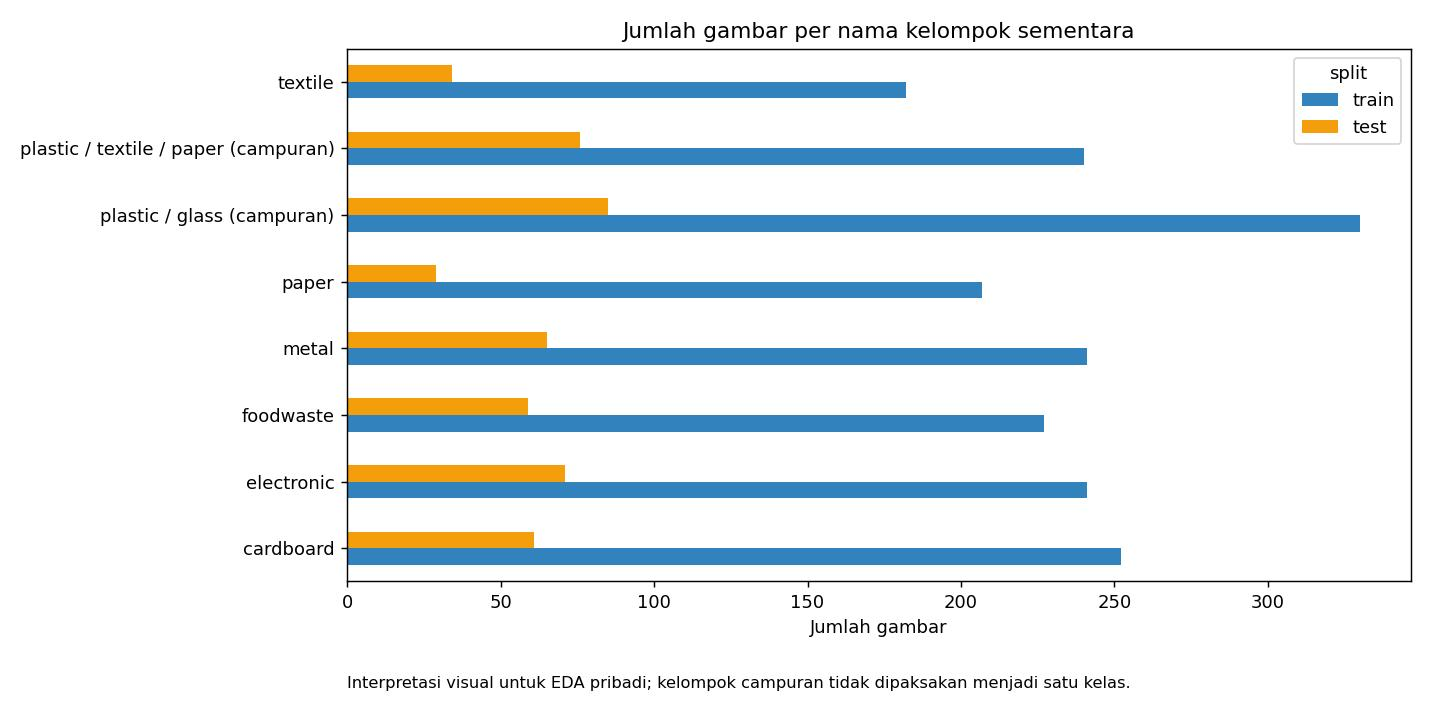

,kelas_resmi,jumlah_train_terverifikasi,jumlah_test_terverifikasi
0,glass,<NA>,<NA>
1,paper,<NA>,<NA>
2,electronic,<NA>,<NA>
3,metal,<NA>,<NA>
4,plastic,<NA>,<NA>
5,cardboard,<NA>,<NA>
6,textile,<NA>,<NA>
7,foodwaste,<NA>,<NA>


,split,width,height,jumlah
169,train,640,640,700
144,train,416,416,579
25,test,416,416,240
31,test,640,640,136
132,train,400,533,74
168,train,640,480,74
210,train,1599,1599,57
111,train,320,320,56
72,train,225,225,39
133,train,400,534,36


,split,ukuran,display_label,jumlah
214,train,416×416,cardboard,237
256,train,640×640,foodwaste,194
219,train,416×416,plastic / glass (campuran),190
255,train,640×640,electronic,180
257,train,640×640,metal,123
258,train,640×640,paper,96
220,train,416×416,plastic / textile / paper (campuran),83
202,train,400×533,textile,74
260,train,640×640,plastic / textile / paper (campuran),74
49,test,640×640,electronic,64


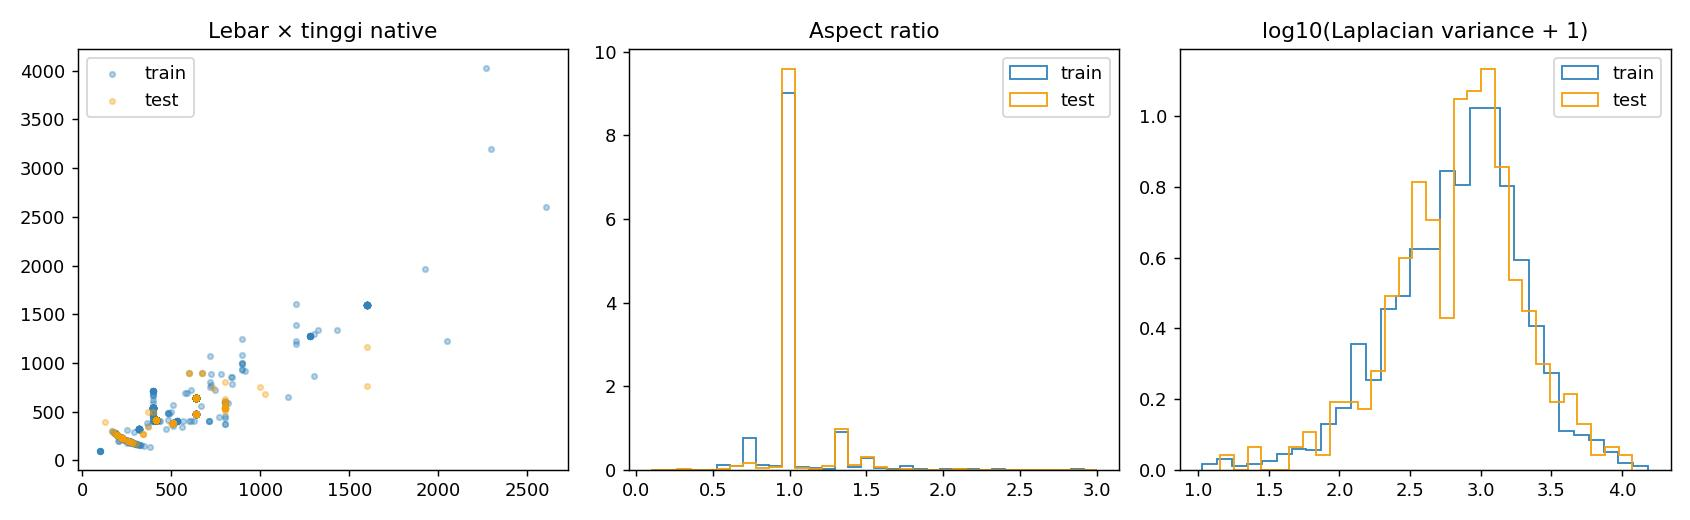

In [3]:
distribution, official_counts, dimensions = audit.distribution_tables(ctx)
display(distribution)
display(DisplayImage(filename=str(audit.REPORT/'figures/distribution.jpg')))
display(official_counts)
display(dimensions.sort_values('jumlah',ascending=False).head(20))
size_names=ctx['df'].assign(ukuran=lambda d:d.width.astype(str)+'×'+d.height.astype(str))
dimension_labels=size_names.groupby(['split','ukuran','display_label']).size().rename('jumlah').reset_index()
dimension_labels.to_csv(audit.REPORT/'dimensions_by_display_name.csv',index=False)
display(dimension_labels.sort_values('jumlah',ascending=False).head(20))
display(DisplayImage(filename=str(audit.REPORT/'figures/dimensions_quality.jpg')))

## 3. Preview train dan test

Sampel acak memakai seed tetap dan tidak dipilih berdasarkan label arsip. Preview test lebih banyak agar cakupan masalah test mudah diperiksa. Caption menampilkan ID gambar, dimensi native, dan nama tampilan sementara.

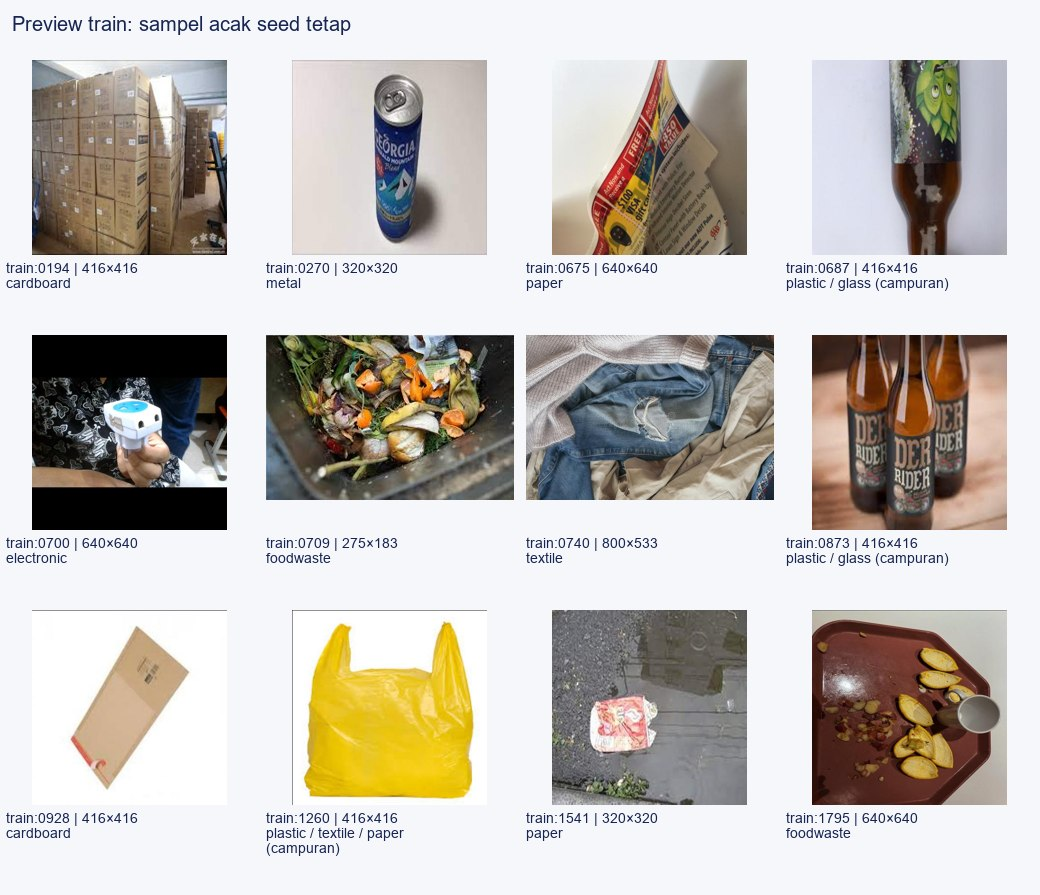

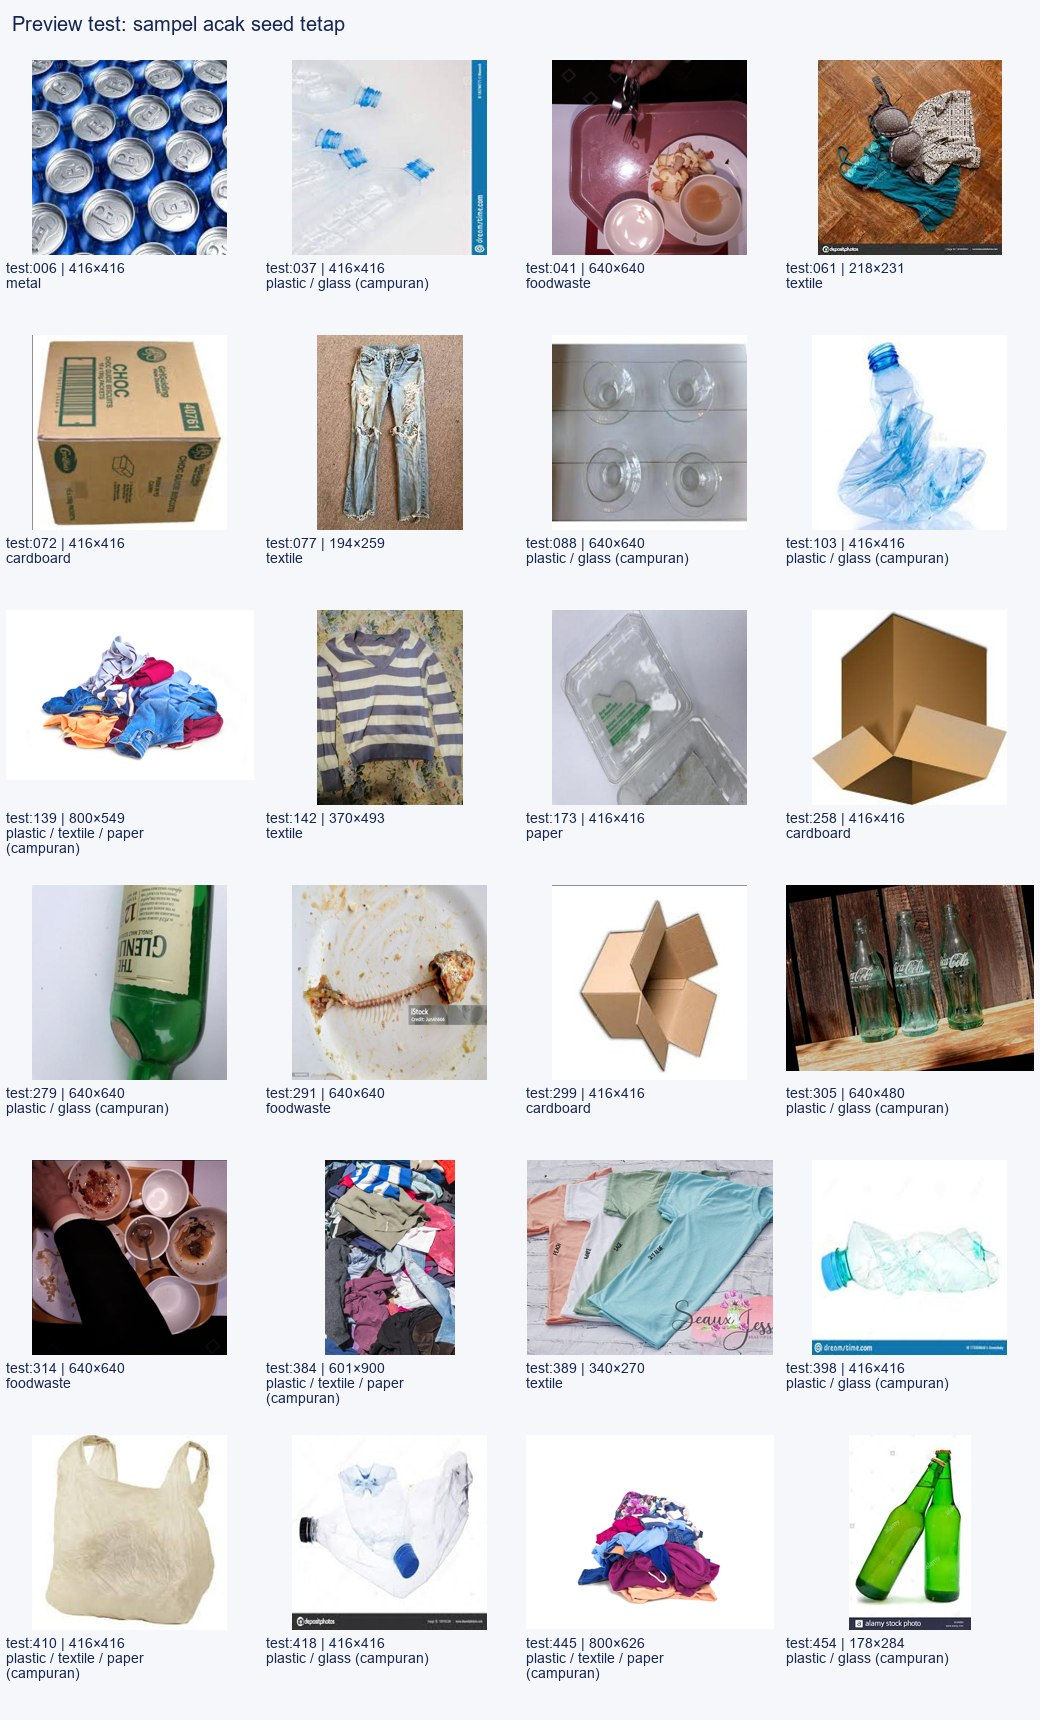

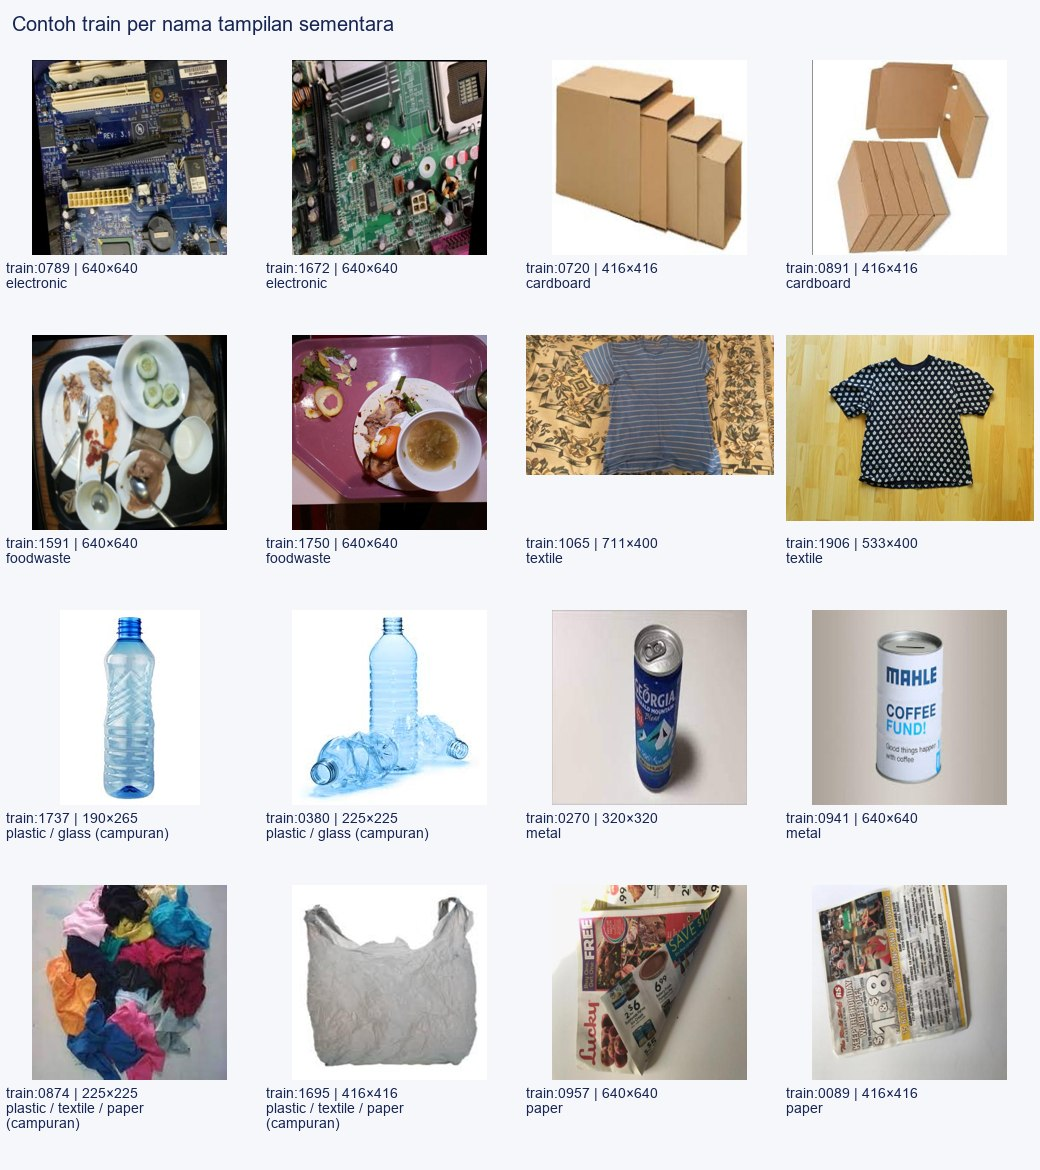

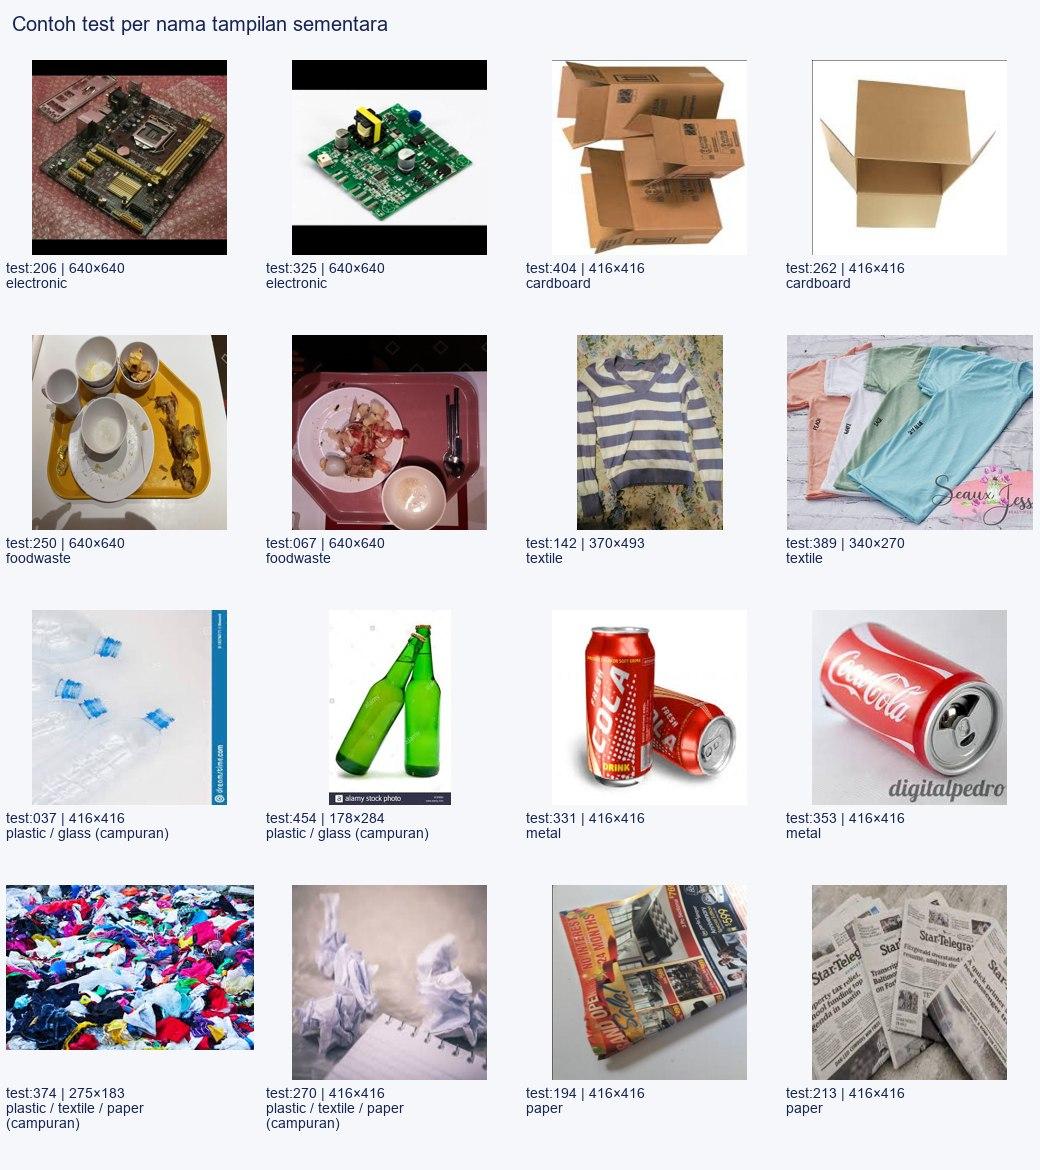

In [4]:
for split,n in [('train',12),('test',24)]:
    rows=ctx['df'][ctx['df'].split.eq(split)].sample(n,random_state=20261106).sort_values('key')
    path=audit.contact_sheet(ctx,rows,f'{split}_random_preview',f'Preview {split}: sampel acak seed tetap')
    display(DisplayImage(filename=str(path)))
for split in ['train','test']:
    rows=pd.concat([g.sort_values('model_margin',ascending=False).head(2) for _,g in ctx['df'][ctx['df'].split.eq(split)].groupby('cluster_index')])
    path=audit.contact_sheet(ctx,rows,f'{split}_named_representatives',f'Contoh {split} per nama tampilan sementara')
    display(DisplayImage(filename=str(path)))

## 4. Gambar berdekatan atau bersentuhan: kandidat region dan crop

Seluruh 2.400 gambar diperiksa. Perbedaan warna Lab terhadap tepi gambar membentuk hipotesis foreground, lalu connected components mencari region terpisah. Jika region menyatu, distance transform dan watershed dengan marker mengusulkan pemisahan.

**Region bukan kepastian objek:** satu benda dapat terpecah menjadi beberapa region; latar ramai juga dapat dianggap foreground. Watershed dapat menghasilkan oversegmentation. Crop hanya kandidat, bukan preprocessing massal yang sudah terbukti meningkatkan Accuracy. Semua koordinat dikembalikan ke piksel native dan hasil crop diuji persis terhadap potongan gambar induk.

Train disimpan di `data/processed/stage3_crop_candidates_v1/train_candidates/<ID>/`; crop test berada di `test_previews/`. Seluruh crop tetap membawa parent ID, hash sumber, candidate-group dan fold induk. Crop test tidak menjadi data train. Label induk tidak diwariskan karena dua region dapat berbeda material.

Dasar metode: [OpenCV watershed](https://docs.opencv.org/4.x/d3/db4/tutorial_py_watershed.html).

Analisis region/crop: 300/2400


Analisis region/crop: 600/2400


Analisis region/crop: 900/2400


Analisis region/crop: 1200/2400


Analisis region/crop: 1500/2400


Analisis region/crop: 1800/2400


... (2 outputs left out)

,gambar,kandidat_beberapa_region
split,,
test,480,246
train,1920,890


,split,proposal_method,jumlah_crop
0,test,connected_components,268
1,test,watershed_markers,359
2,train,connected_components,808
3,train,watershed_markers,1363


,parent_key,split,x0,y0,x1,y1,crop_width,crop_height,parent_fold,augmentation_candidate,label_status
0,train:0001,train,67,187,338,407,271,220,1.0,False,unlabeled_algorithmic_candidate
1,train:0001,train,163,23,317,210,154,187,1.0,False,unlabeled_algorithmic_candidate
2,train:0003,train,0,0,341,683,341,683,2.0,False,unlabeled_algorithmic_candidate
3,train:0003,train,185,410,324,674,139,264,2.0,False,unlabeled_algorithmic_candidate
4,train:0005,train,45,6,499,640,454,634,4.0,False,unlabeled_algorithmic_candidate
5,train:0005,train,288,0,640,390,352,390,4.0,False,unlabeled_algorithmic_candidate
6,train:0006,train,0,326,416,416,416,90,3.0,False,unlabeled_algorithmic_candidate
7,train:0006,train,99,42,358,149,259,107,3.0,False,unlabeled_algorithmic_candidate
8,train:0008,train,24,137,386,369,362,232,1.0,False,unlabeled_algorithmic_candidate
9,train:0008,train,152,23,379,253,227,230,1.0,False,unlabeled_algorithmic_candidate


split,test,train
indikator,,
flag_low_sharpness,26,96
flag_exposure,11,40
flag_low_contrast,21,96
flag_busy_texture,21,96
flag_novel_appearance,27,96
flag_model_ambiguous,179,634
possible_multiple_regions,246,890


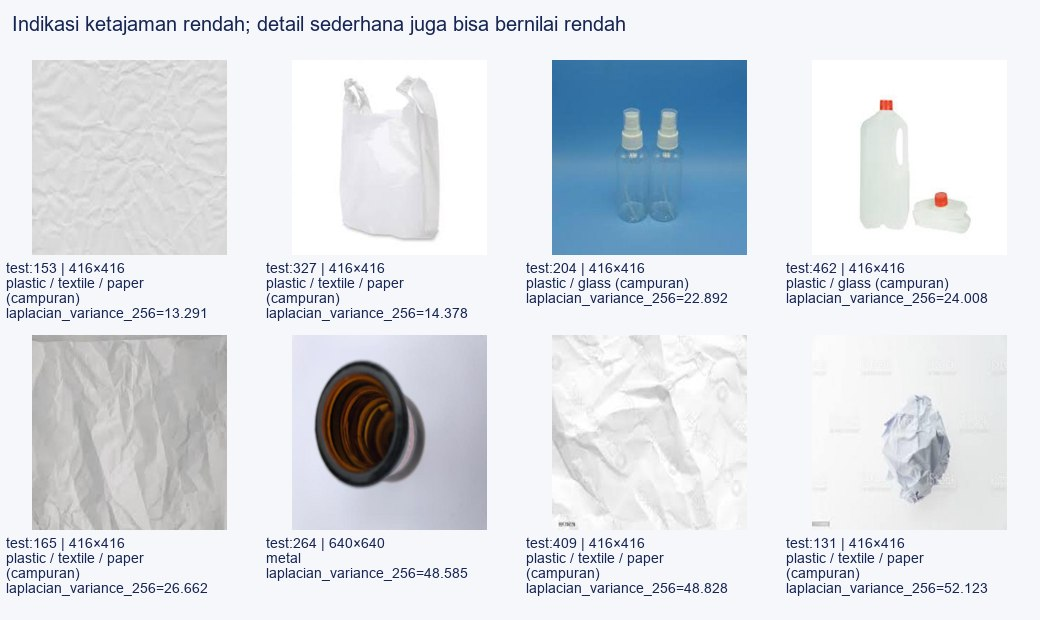

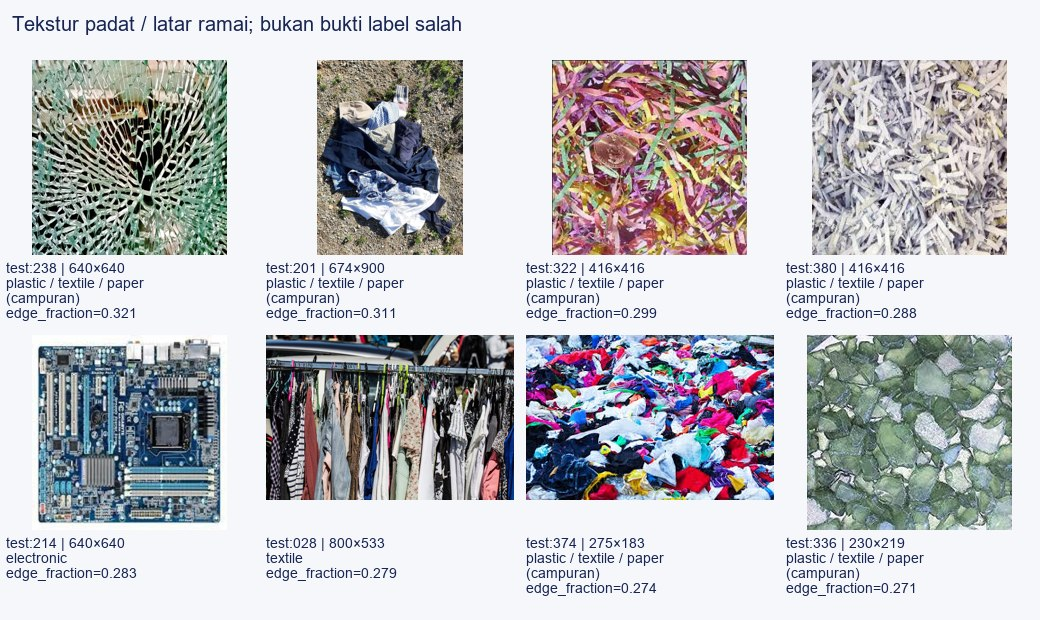

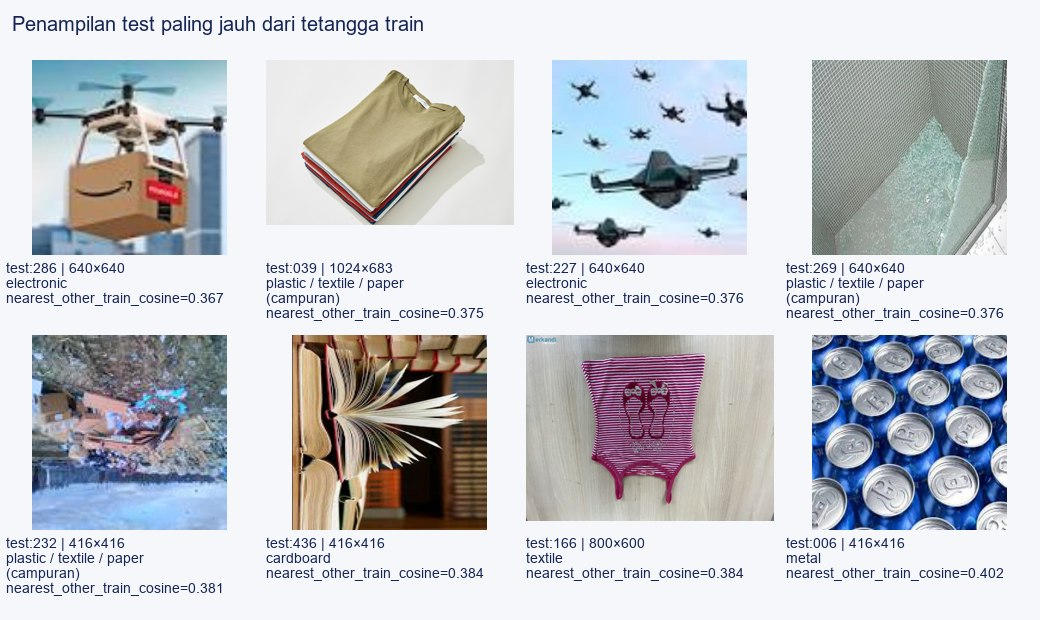

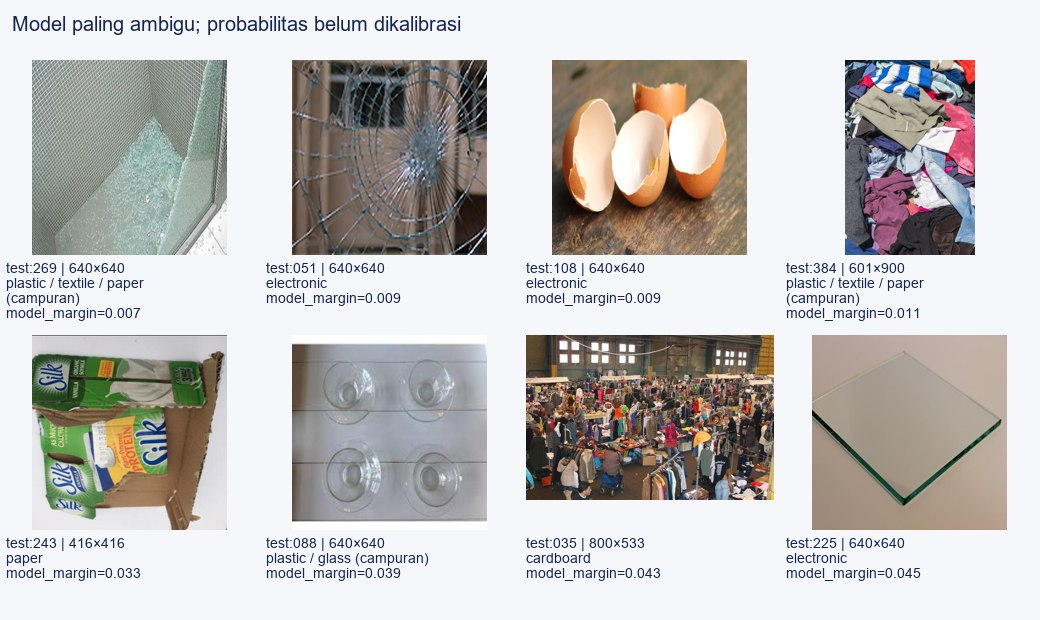

In [5]:
regions, crop_manifest = audit.crop_audit(ctx)
display(regions.groupby('split').agg(gambar=('key','size'),kandidat_beberapa_region=('possible_multiple_regions','sum')))
display(crop_manifest.groupby(['split','proposal_method']).size().rename('jumlah_crop').reset_index())
display(crop_manifest[['parent_key','split','x0','y0','x1','y1','crop_width','crop_height','parent_fold','augmentation_candidate','label_status']].head(15))
previews,flag_counts = audit.make_previews(ctx)
display(flag_counts)
for name in ['test_low_sharpness','test_busy_scene','test_novel_appearance','test_ambiguous']:
    display(DisplayImage(filename=str(previews[name])))

## 5. Preview masalah test dan dampak crop

Ketajaman memakai Laplacian variance pada ukuran terkontrol; permukaan polos bisa bernilai rendah tanpa blur. Tepi padat menandai tekstur/latar ramai, bukan label acak. Jarak embedding dan margin head memberi daftar kasus model ragu. Batas teknis berasal dari train, bukan tuning terhadap test.

Probe crop dipilih dengan seed tetap: maksimal 96 crop train dan 48 crop test. Head yang sama membandingkan crop dan flip-nya dengan prediksi gambar penuh. Perbedaan hasil menunjukkan sensitivitas konteks, bukan bukti crop lebih benar. Probabilitas belum dikalibrasi. Tidak ada crop yang dipromosikan menjadi target training.

Preview di bawah memperlihatkan sumber dengan kotak kandidat dan potongannya. Metode ini juga memiliki kegagalan pada benda panjang/tekstur atau objek yang menyentuh tepi.

D:\lomba\NSC UB\GELAR-RASA\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Probe crop direct: 144 tampilan


Probe crop hflip: 144 tampilan


,crop_diuji,berbeda_dari_gambar_penuh,stabil_flip
split,,,
test,48,6,48
train,96,13,93


,parent_key,split,parent_display_label,crop_display_label,crop_probability_uncalibrated,crop_changed_model_group,crop_flip_stable
0,test:003,test,foodwaste,foodwaste,0.801461,False,True
1,test:004,test,metal,electronic,0.614937,True,True
2,test:012,test,plastic / glass (campuran),plastic / glass (campuran),0.996000,False,True
3,test:015,test,electronic,electronic,0.847604,False,True
4,test:021,test,foodwaste,foodwaste,0.999767,False,True
5,test:025,test,foodwaste,foodwaste,0.958251,False,True
6,test:042,test,foodwaste,electronic,0.494002,True,True
7,test:052,test,foodwaste,foodwaste,0.525722,False,True
8,test:055,test,metal,metal,0.999230,False,True
9,test:057,test,plastic / glass (campuran),plastic / glass (campuran),0.647266,False,True


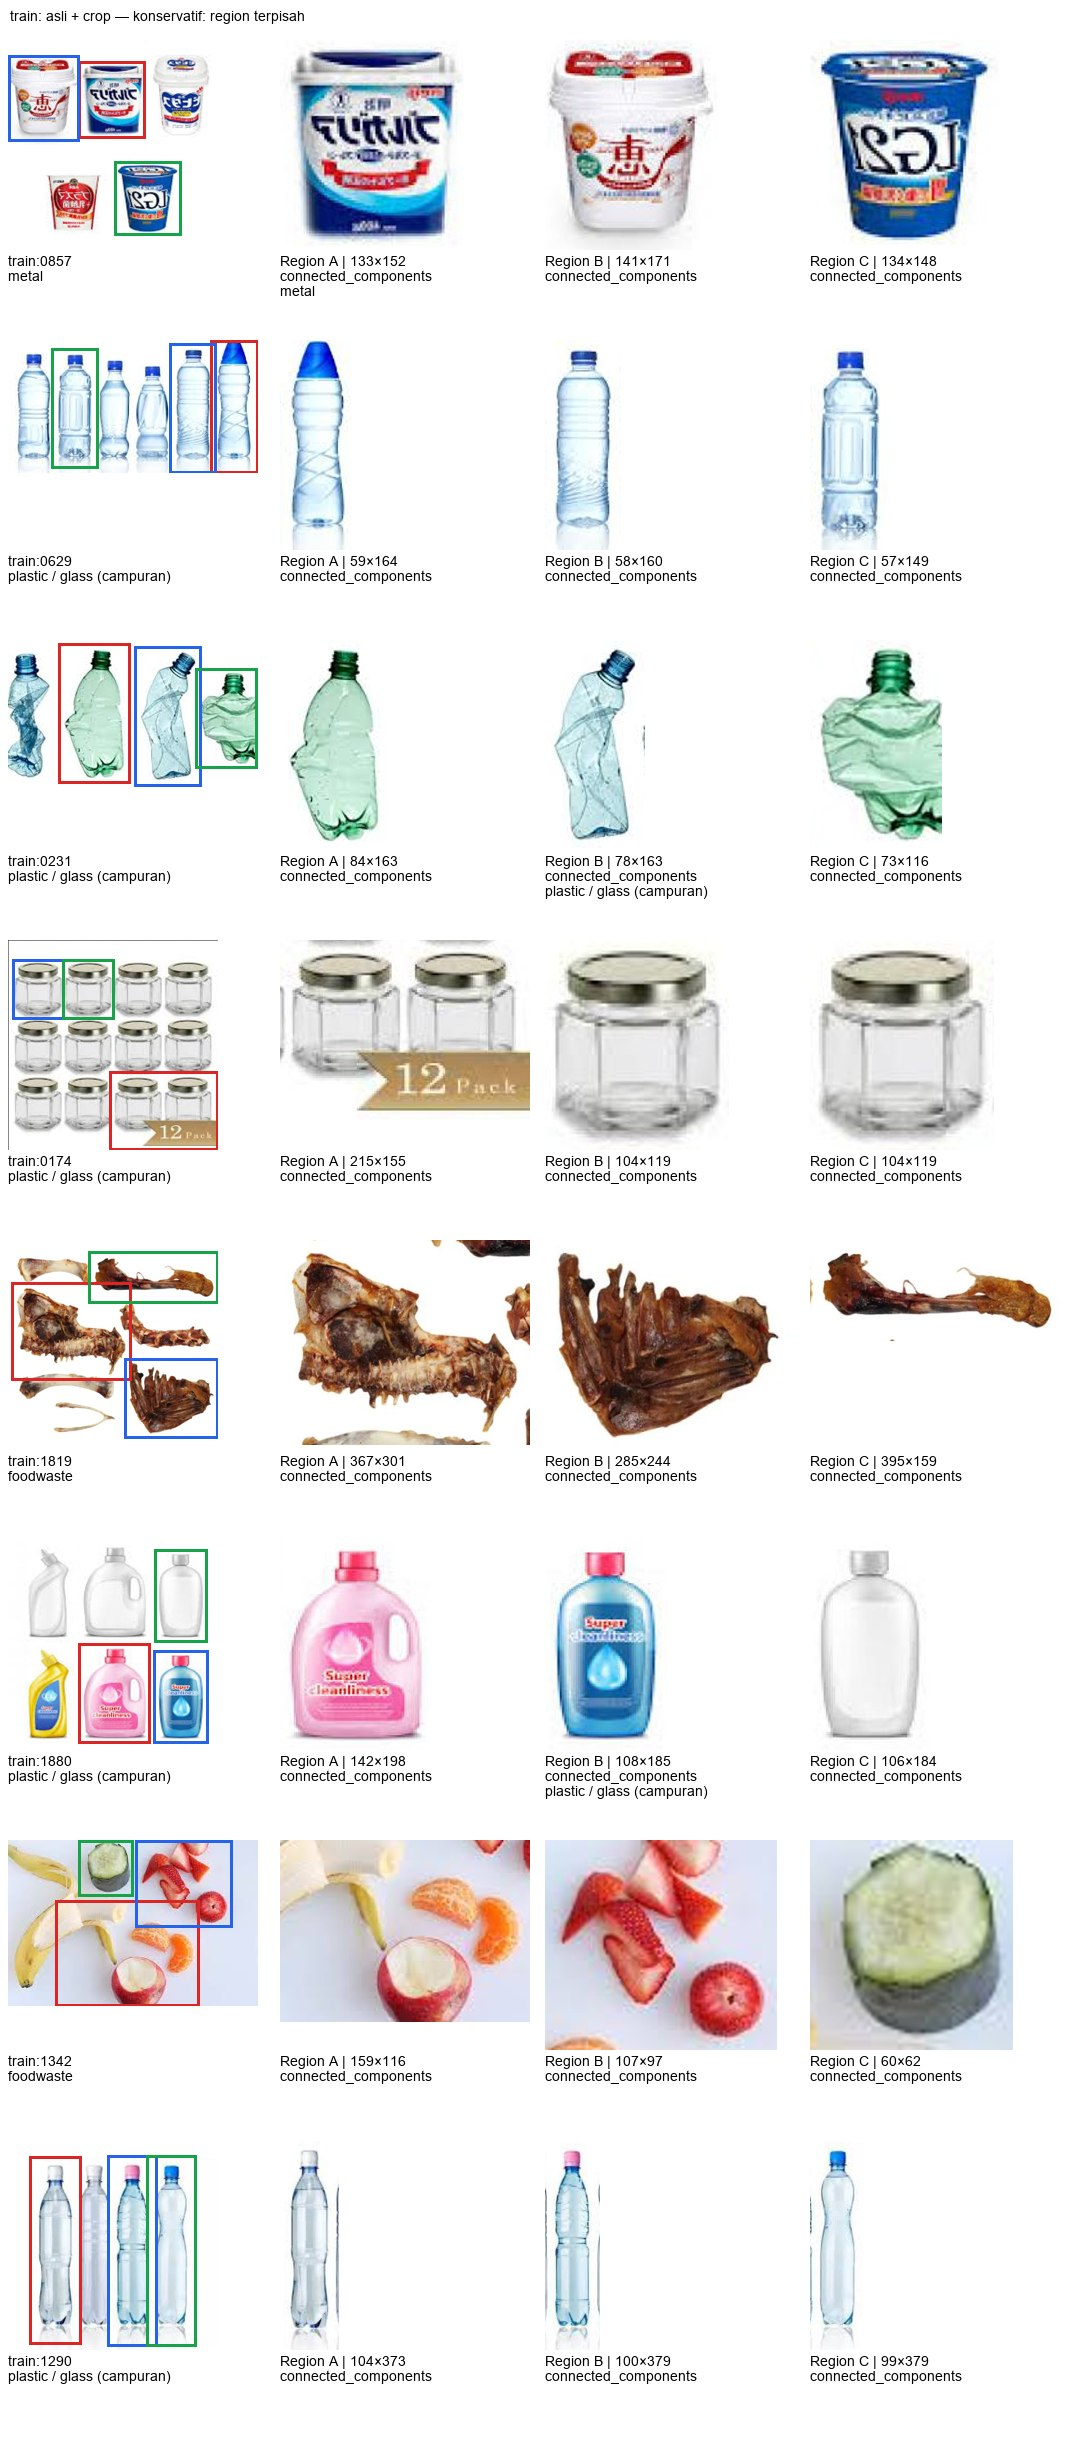

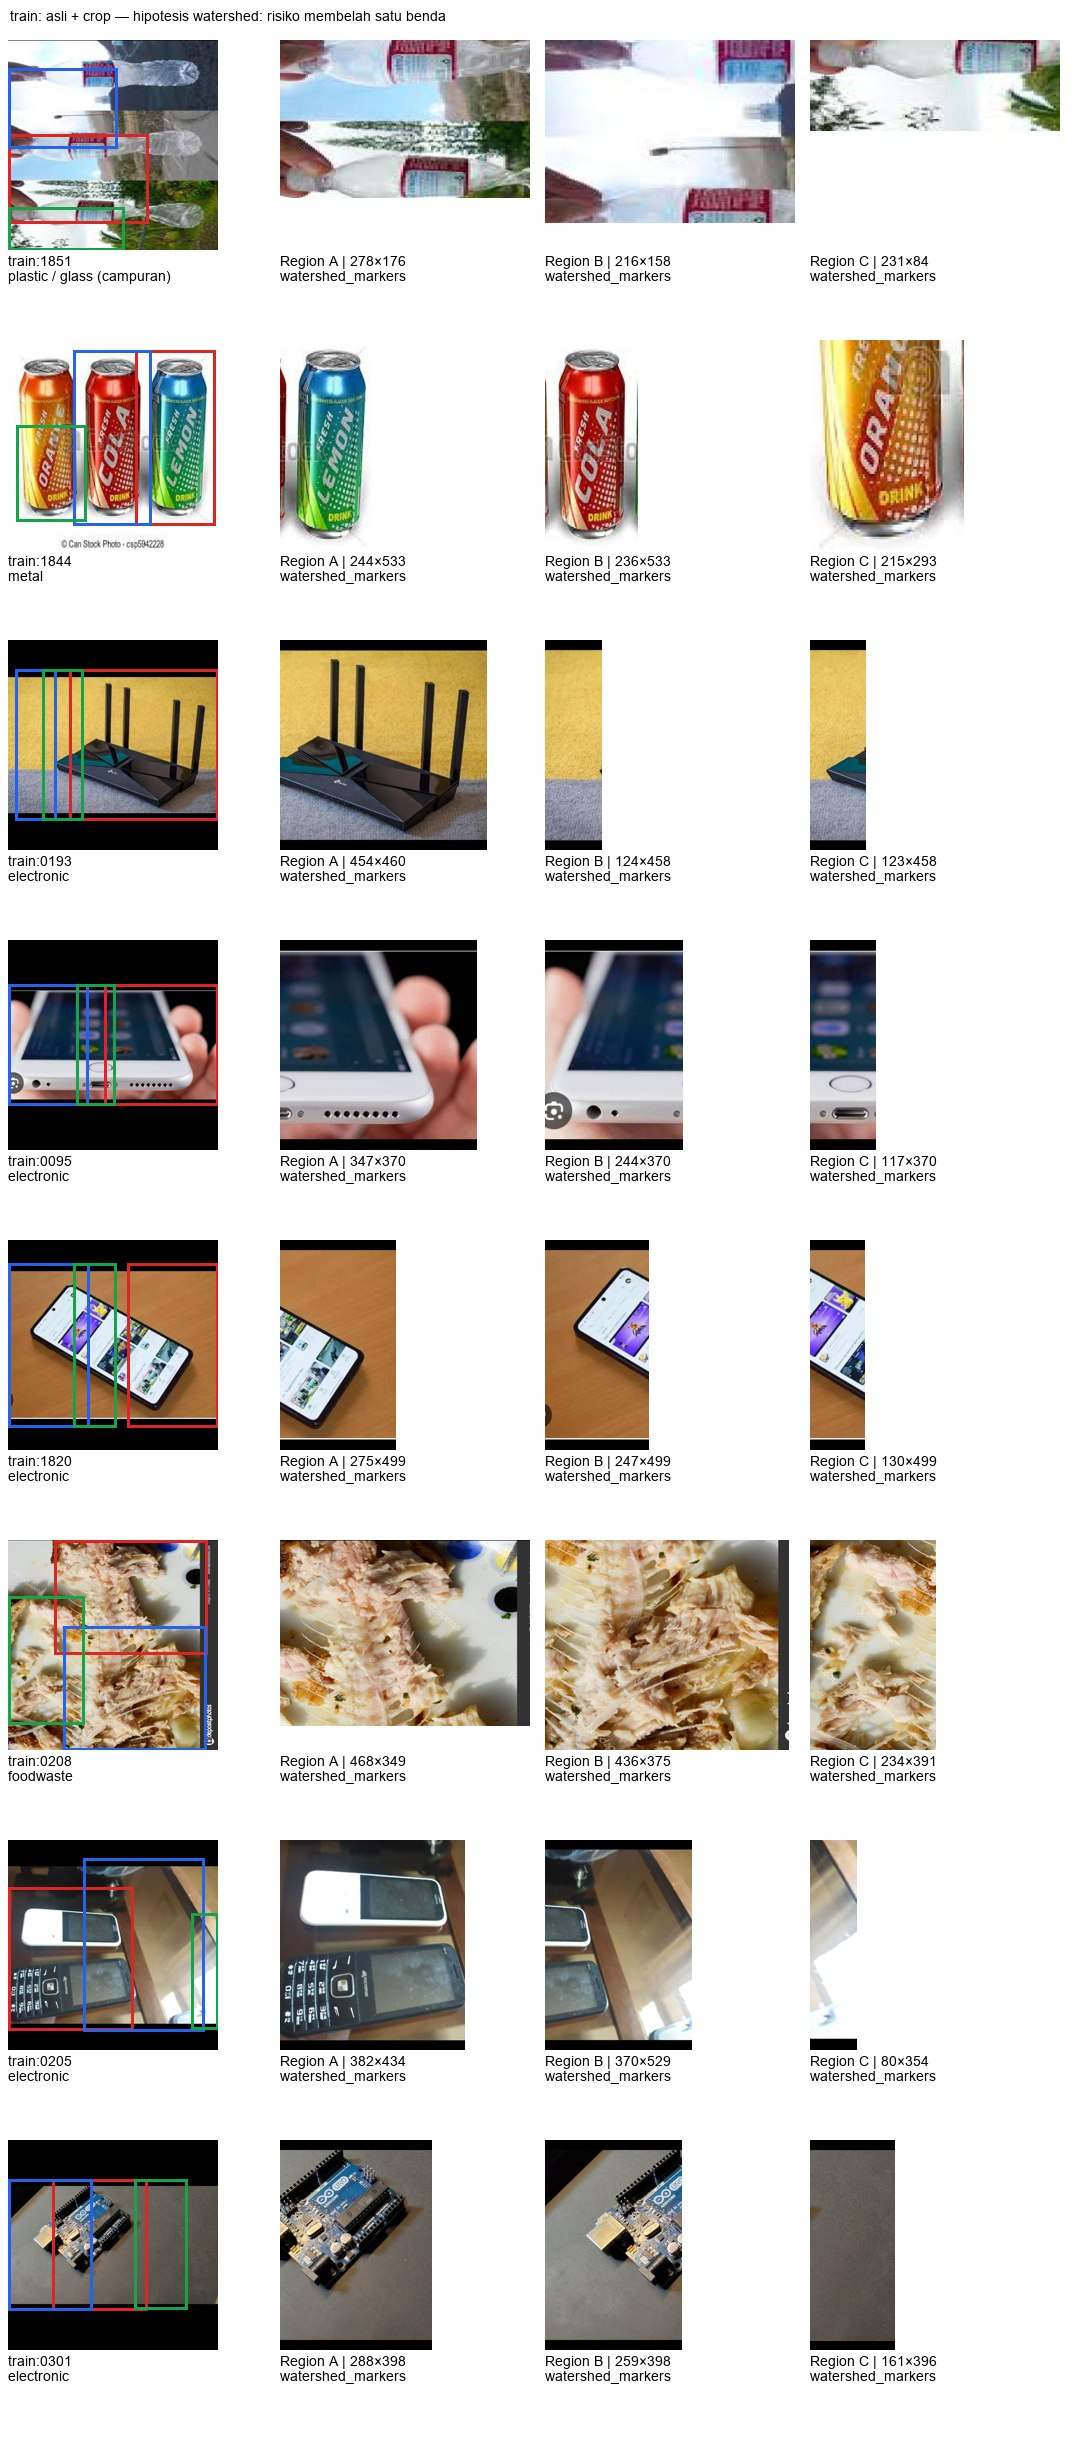

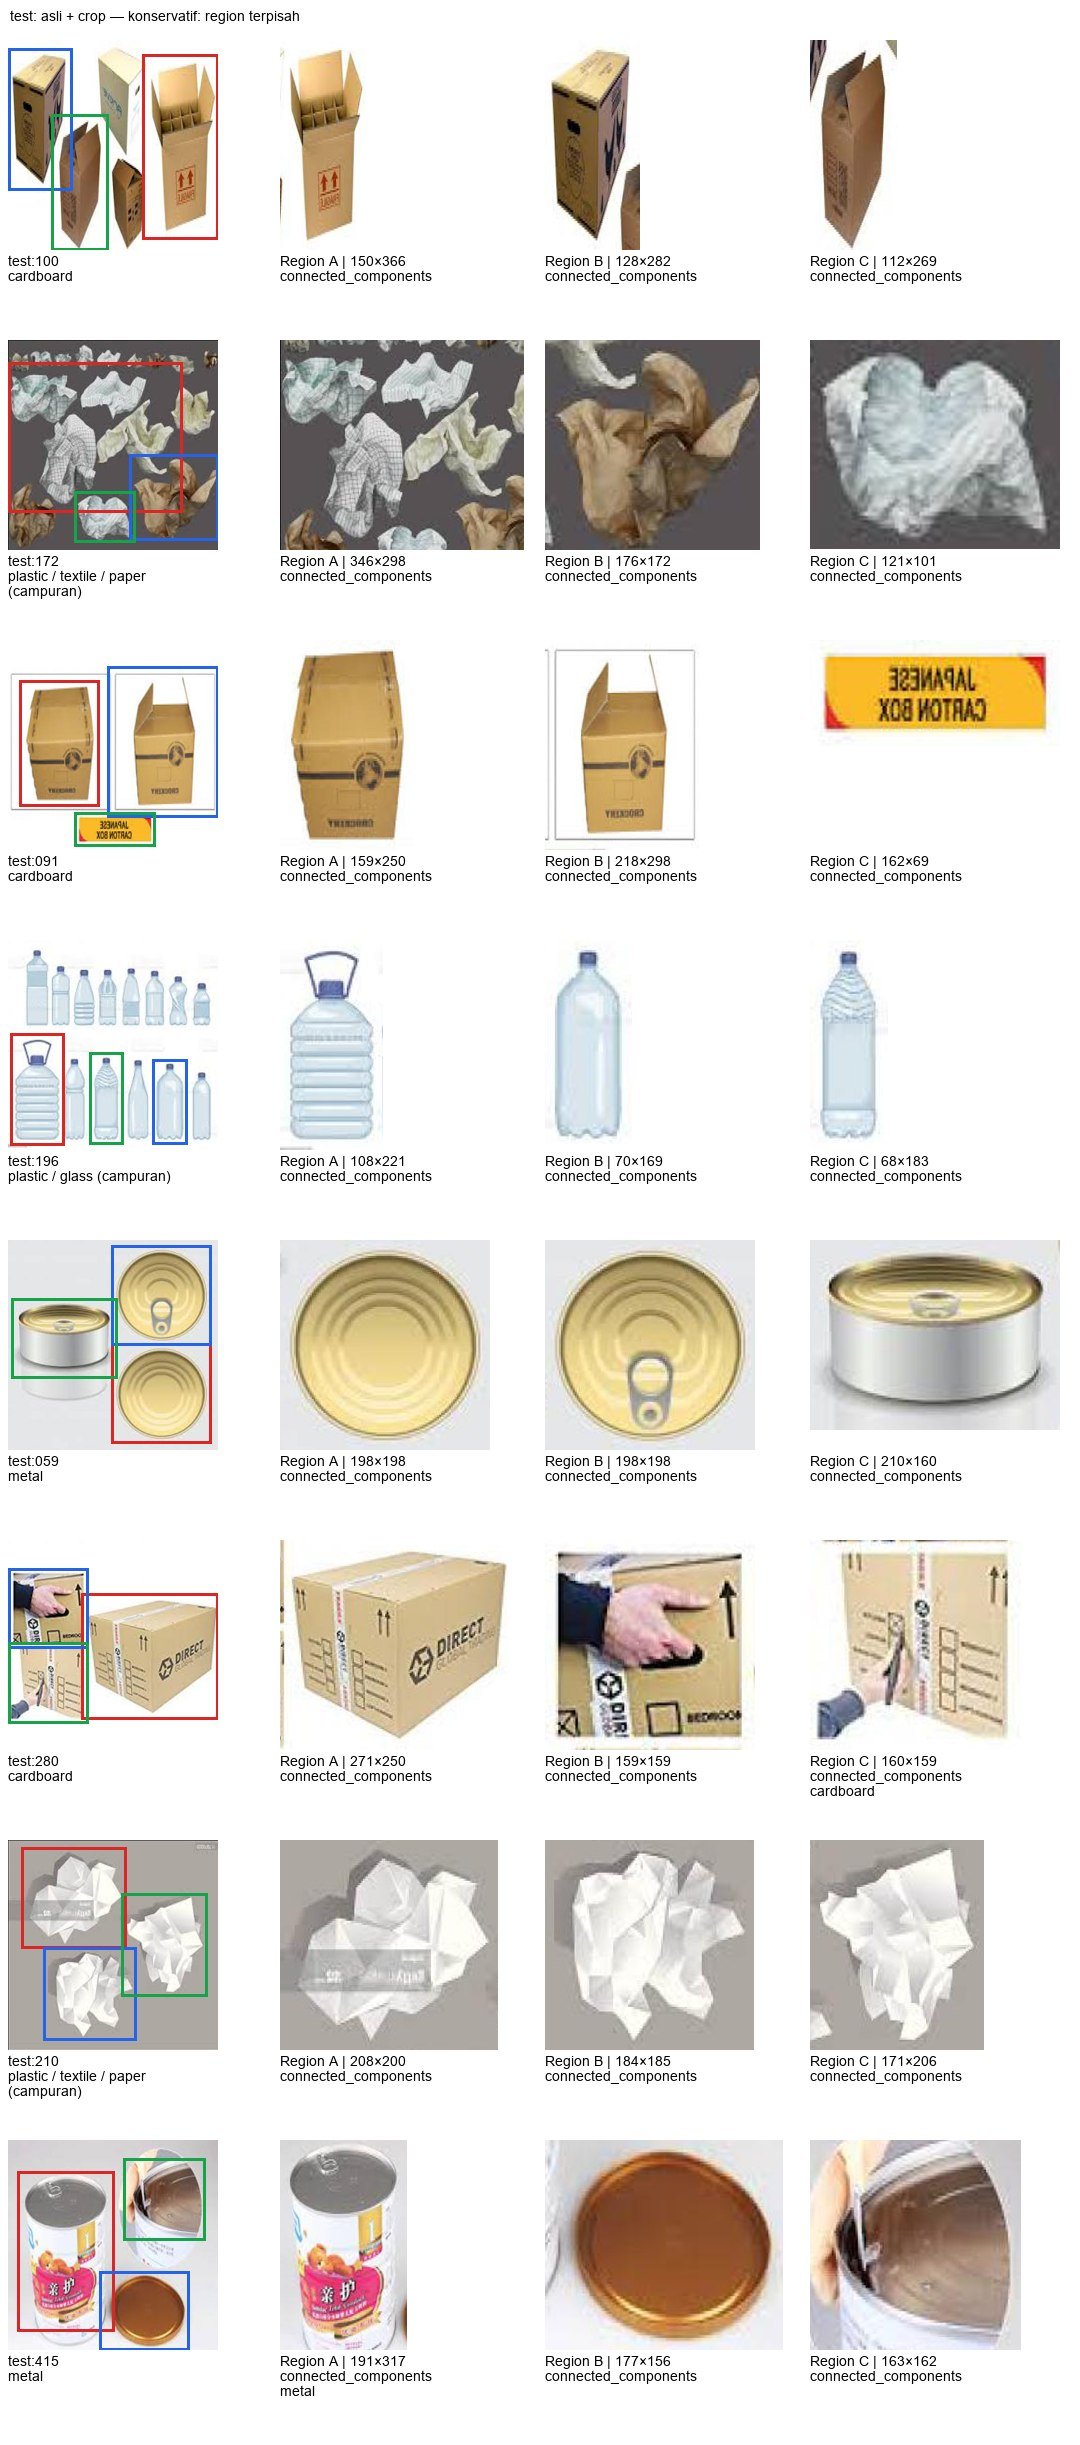

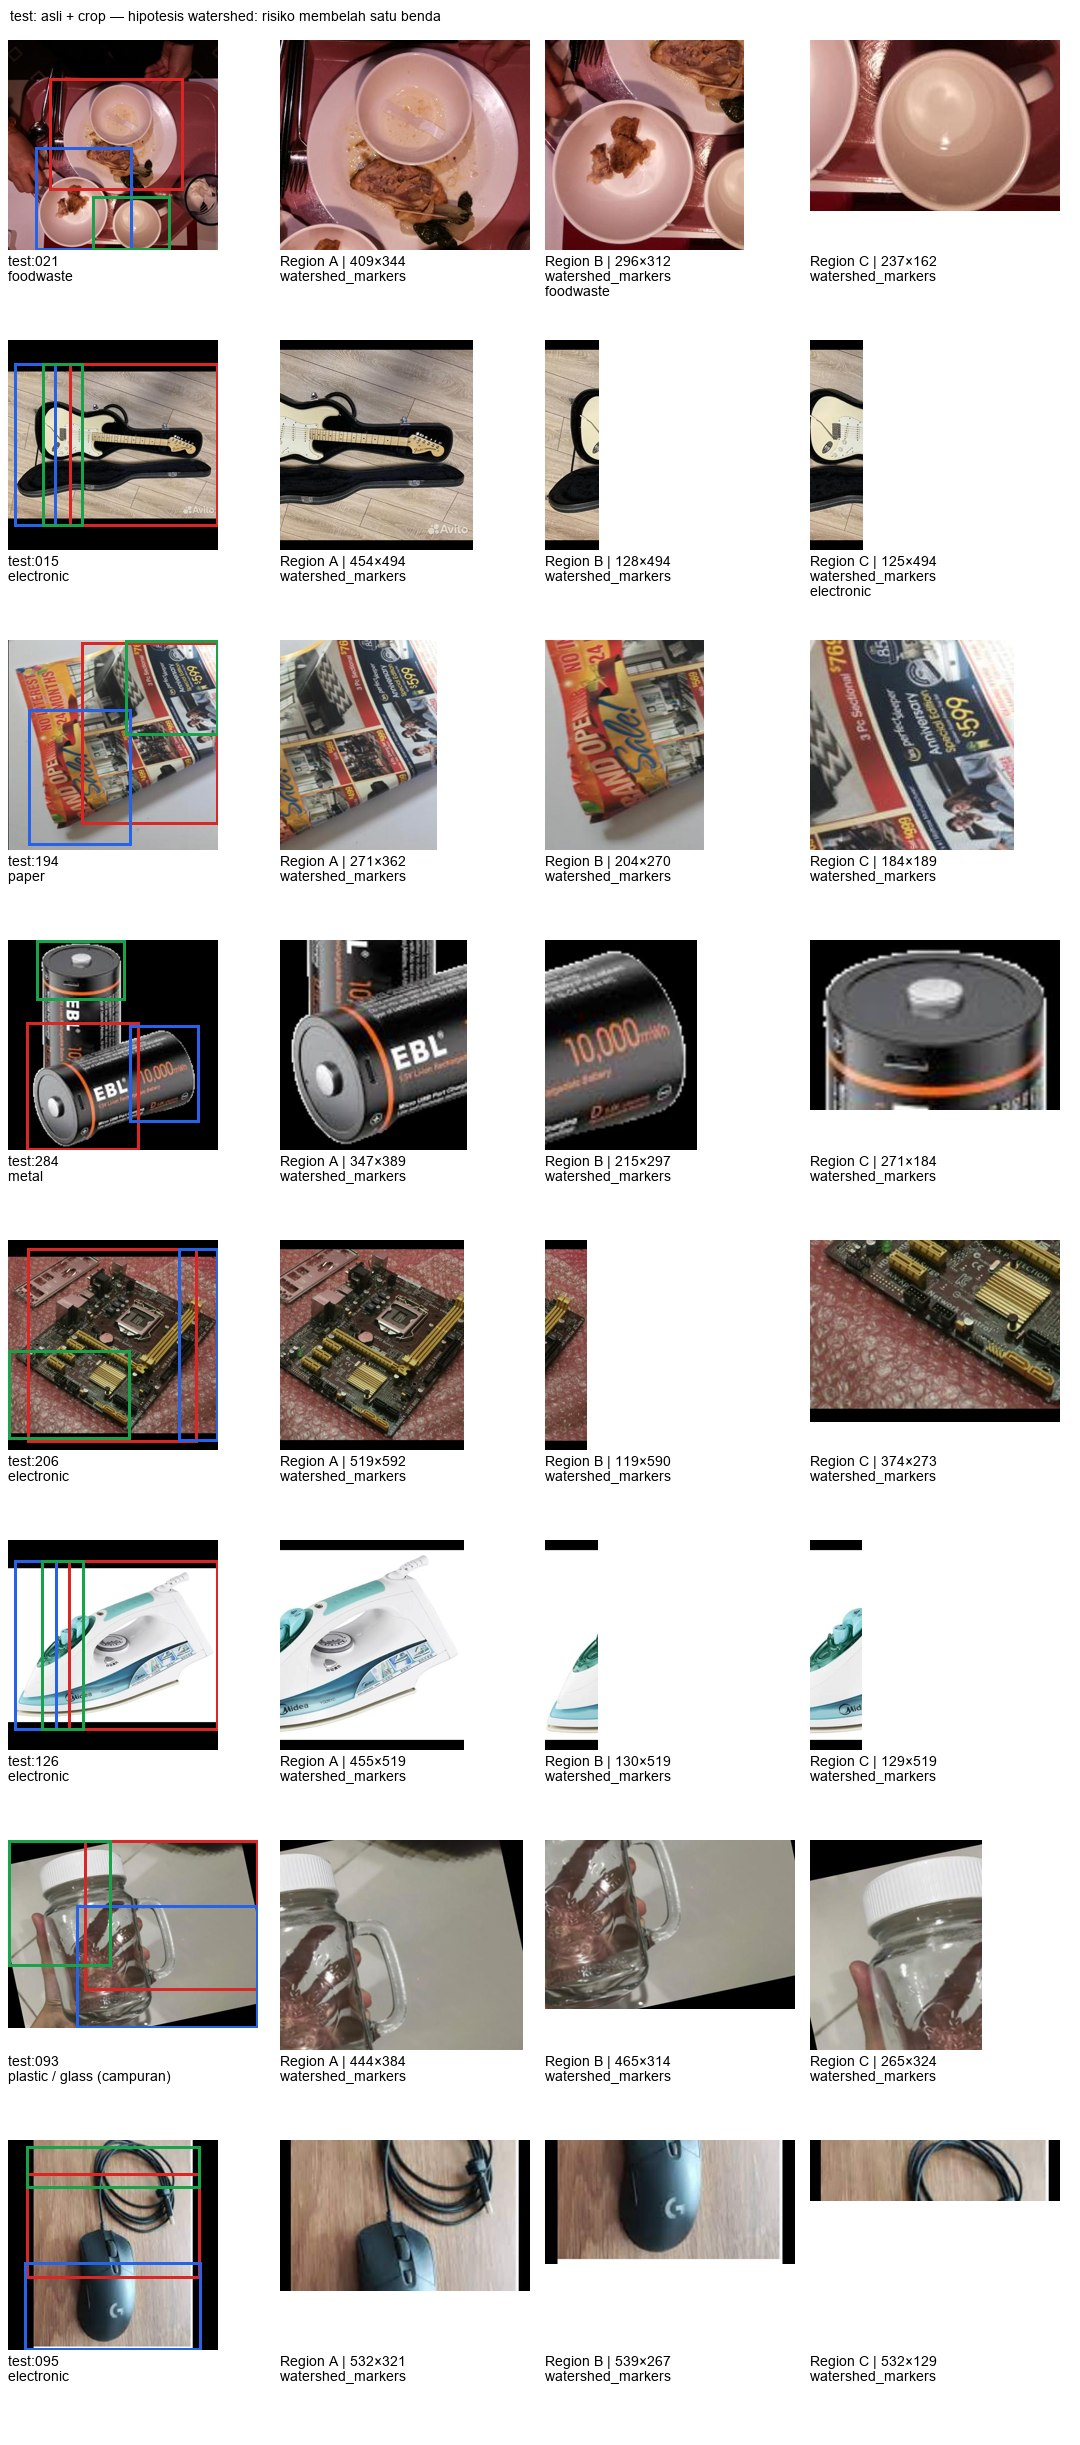

Kandidat konservatif train: 174 crop dari 68 gambar induk; belum menjadi label training.


In [6]:
crop_probe = audit.crop_model_probe(ctx)
if not crop_probe.empty:
    display(crop_probe.groupby('split').agg(crop_diuji=('crop_key','size'),berbeda_dari_gambar_penuh=('crop_changed_model_group','sum'),stabil_flip=('crop_flip_stable','sum')))
    display(crop_probe[['parent_key','split','parent_display_label','crop_display_label','crop_probability_uncalibrated','crop_changed_model_group','crop_flip_stable']].head(16))
for split in ['train','test']:
    for method in ['connected_components','watershed_markers']:
        display(DisplayImage(filename=str(audit.crop_previews(ctx,split,method))))
conservative=crop_manifest[crop_manifest.augmentation_candidate]
print('Kandidat konservatif train:',len(conservative),'crop dari',conservative.parent_key.nunique(),'gambar induk; belum menjadi label training.')

## 6. Kemiripan piksel seluruh test–train

Pencarian RGB MSE 64×64 dilakukan pada semua **480×1.920 pasangan**, termasuk horizontal flip. SSIM 128×128 kemudian dihitung pada gabungan kandidat RGB, flip, pHash, dan embedding. Ini pencarian SSIM pada shortlist, bukan SSIM menyeluruh untuk semua pasangan.

Skor setelah resize dapat tinggi karena latar serupa. Karena itu, tampilkan juga ukuran native, beda aspect ratio, hash byte, hash piksel, dan MAE native bila ukuran memungkinkan. Heatmap memperlihatkan selisih setelah alignment. Kesamaan ukuran sendiri bukan bukti gambar sama atau label sama.

[Definisi dan parameter SSIM](https://scikit-image.org/docs/stable/api/skimage.metrics.html#skimage.metrics.structural_similarity): `data_range=255` dinyatakan eksplisit. Resize full-frame untuk pengukuran dicatat sebagai transform yang dapat mendistorsi aspect ratio.

Kemiripan piksel+SSIM: 120/480 test


Kemiripan piksel+SSIM: 240/480 test


Kemiripan piksel+SSIM: 360/480 test


Kemiripan piksel+SSIM: 480/480 test


,test_key,train_key,test_display_label,train_display_label,ssim128_best,same_native_dimensions,pixel_identical,train_images_with_test_dimensions
1,test:001,train:1096,textile,plastic / glass (campuran),0.222017,False,False,0
13,test:002,train:0280,foodwaste,foodwaste,0.328056,True,False,700
25,test:003,train:0894,foodwaste,foodwaste,0.320942,True,False,700
30,test:004,train:0038,metal,plastic / textile / paper (campuran),0.321163,False,False,579
46,test:005,train:0384,paper,plastic / textile / paper (campuran),0.564596,False,False,579
49,test:006,train:1864,metal,plastic / glass (campuran),0.074677,False,False,579
57,test:007,train:1799,foodwaste,plastic / glass (campuran),0.519089,False,False,700
68,test:008,train:0298,cardboard,cardboard,0.457570,True,False,579
79,test:009,train:0880,plastic / glass (campuran),plastic / glass (campuran),0.564726,False,False,1
87,test:010,train:1167,plastic / glass (campuran),plastic / glass (campuran),0.414878,True,False,579


test  median_ssim
same_native_dimensions pixel_identical                   
False                  False             285     0.447054
True                   False             192     0.466651
                       True                3     1.000000

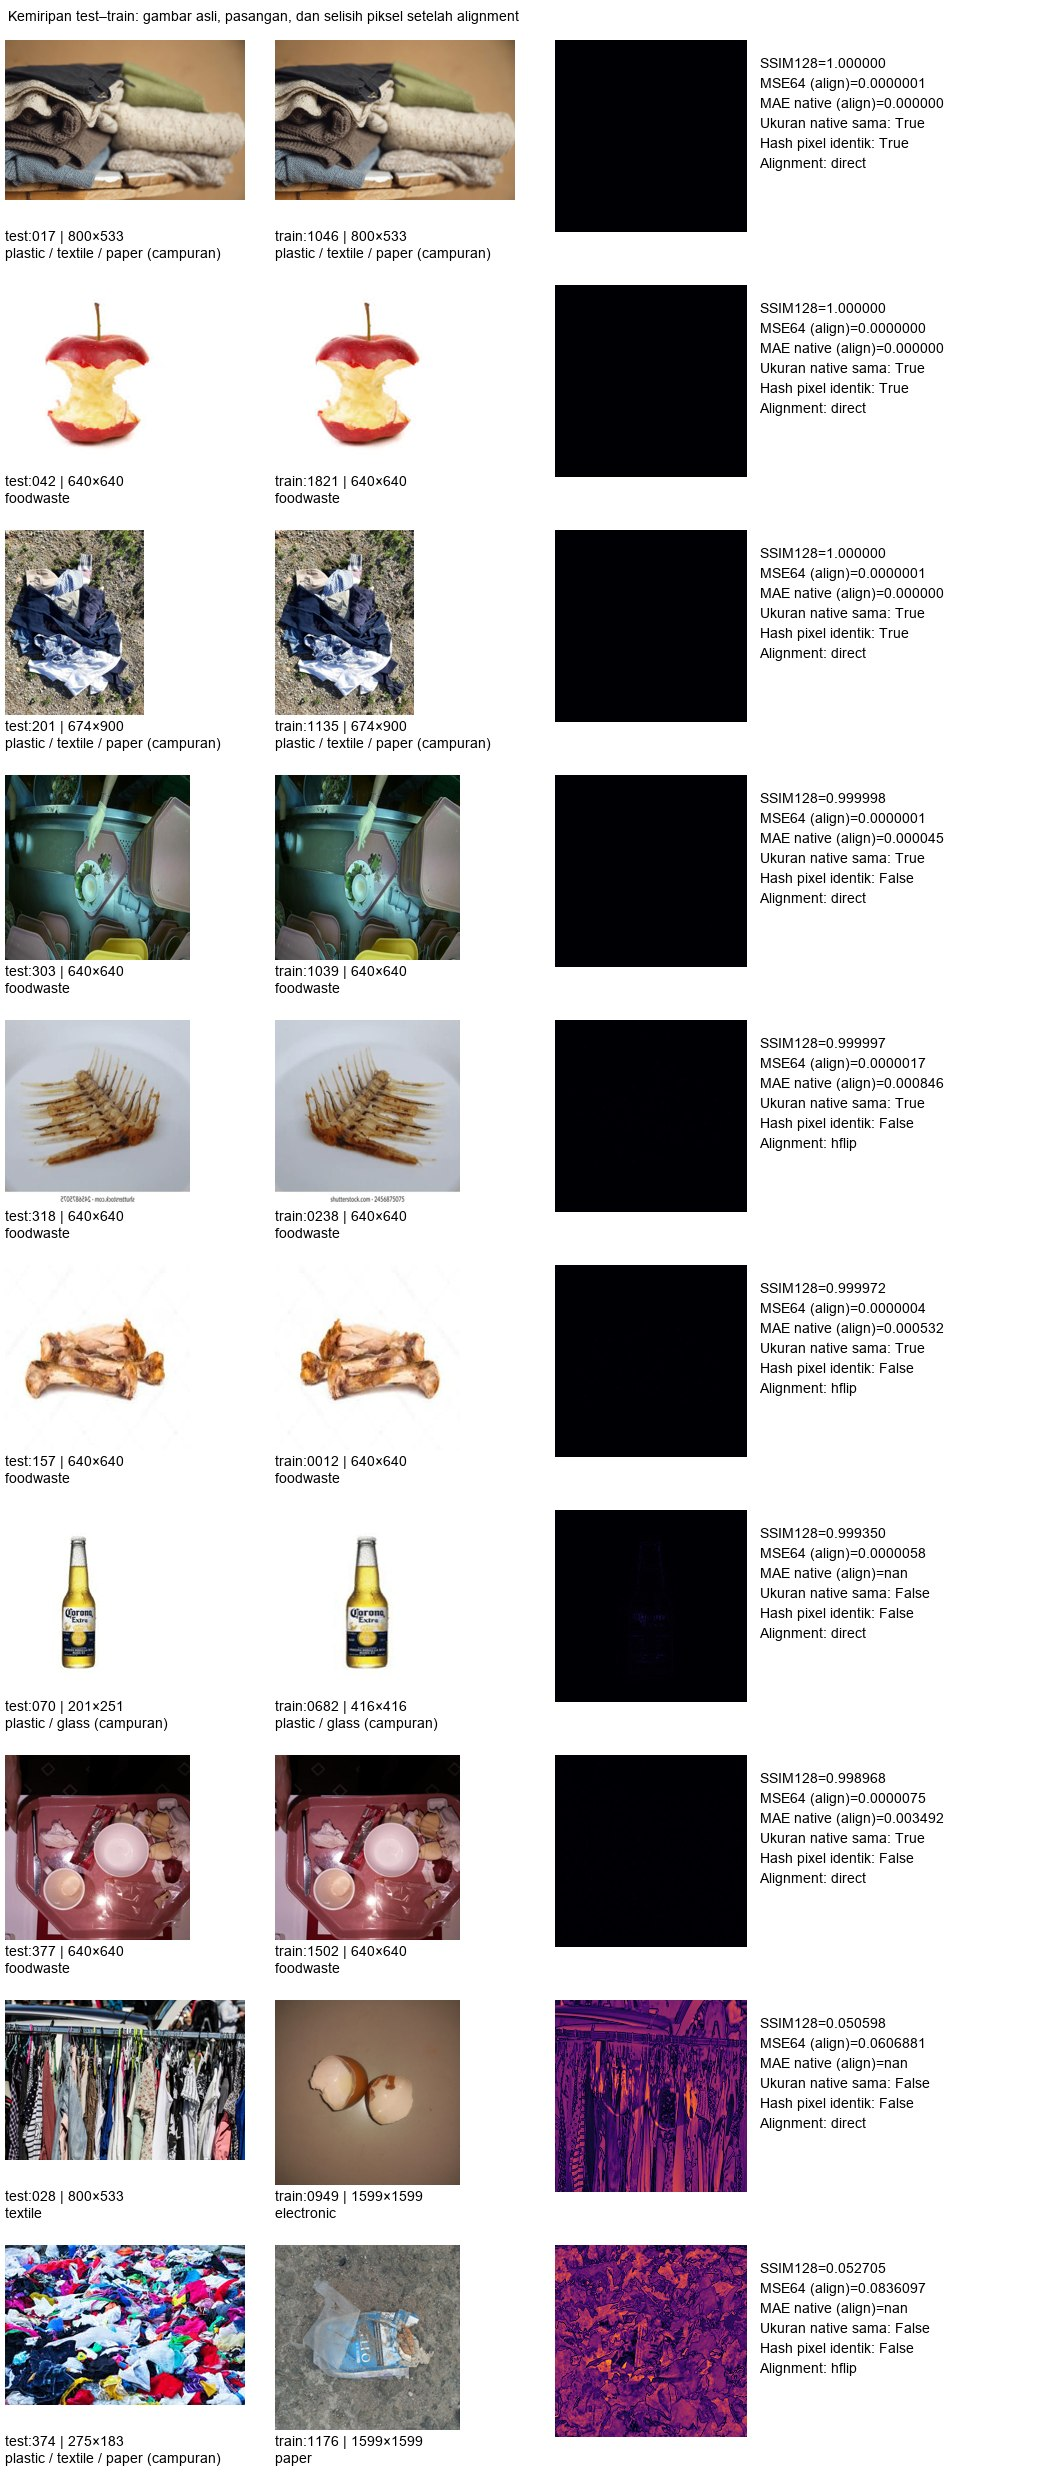

Test pixel identik dengan train: 3
Kandidat SSIM>=0.99: 29
Kandidat setelah saringan MSE/aspect ratio: 19
Test dengan ukuran native tersedia di train: 439
Saringan kemiripan adalah kandidat, bukan pembuktian kategori atau kesamaan sumber.


**Cakupan:** setiap test mendapat satu tetangga terbaik pada shortlist; ini bukan label test terverifikasi.

In [7]:
pixel_pairs, pixel_best = audit.pixel_neighbors(ctx)
display(pixel_best[['test_key','train_key','test_display_label','train_display_label','ssim128_best','same_native_dimensions','pixel_identical','train_images_with_test_dimensions']].head(20))
display(pixel_best.groupby(['same_native_dimensions','pixel_identical']).agg(test=('test_key','size'),median_ssim=('ssim128_best','median')))
display(DisplayImage(filename=str(audit.similarity_previews(ctx))))
pixel_stats=json.loads((audit.REPORT/'pixel_method.json').read_text())
print('Test pixel identik dengan train:',pixel_stats['exact_pixel_test_count'])
print('Kandidat SSIM>=0.99:',pixel_stats['ssim_ge_099_candidates'])
print('Kandidat setelah saringan MSE/aspect ratio:',pixel_stats['conservative_similarity_candidates'])
print('Test dengan ukuran native tersedia di train:',pixel_stats['test_same_size_available'])
print('Saringan kemiripan adalah kandidat, bukan pembuktian kategori atau kesamaan sumber.')
display(Markdown('**Cakupan:** setiap test mendapat satu tetangga terbaik pada shortlist; ini bukan label test terverifikasi.'))

## 7. Seluruh 480 test: galeri berhalaman

Galeri mencakup setiap test tepat sekali, dengan gambar sumber, tetangga train, dimensi, SSIM, dan flag teknis. Gambar tidak dihapus karena blur, ambigu, atau berbeda metode. File galeri dan gambar berada lokal; dataset/gambar terpisah tidak di-push.

In [8]:
gallery = audit.all_test_gallery(ctx)
print('Galeri:',gallery)
display(Markdown('[Buka indeks galeri 480 test](../reports/eda/stage3_visual_20261106/galleries/index.html)'))
display(ctx['df'].groupby('split')[['flag_low_sharpness','flag_exposure','flag_novel_appearance','possible_multiple_regions']].sum())

Galeri: D:\lomba\NSC UB\GELAR-RASA\reports\eda\stage3_visual_20261106\galleries\index.html


[Buka indeks galeri 480 test](../reports/eda/stage3_visual_20261106/galleries/index.html)

,flag_low_sharpness,flag_exposure,flag_novel_appearance,possible_multiple_regions
split,,,,
test,26,11,27,246
train,96,40,96,890


## 8. Keputusan preprocessing dan pemeriksaan akhir

1. Native RGB dan gambar penuh dipertahankan sebagai acuan. Tidak ada auto-drop atau koreksi label per gambar.
2. Crop region disimpan untuk eksperimen terkontrol. Connected components pada latar seragam lebih konservatif; watershed tetap hipotesis yang berisiko memotong satu benda menjadi dua.
3. Train/validasi harus dipisah berdasarkan kelompok induk sebelum menggunakan crop. Semua turunan satu sumber mengikuti fold yang sama.
4. Test tetap satu baris per gambar pada tugas single-label. Memilih salah satu objek test membutuhkan aturan/model yang telah divalidasi; jumlah objek tidak mengubah format submission.
5. Jumlah nama tampilan campuran menunjukkan keterbatasan partisi model. Menamai ulang saja belum menghasilkan classifier delapan material atau Accuracy kategori.

Sel terakhir memastikan sumber model tetap identik. Crop tidak mengubah bobot, label training, atau assignment baseline.

In [9]:
summary = audit.finalize(ctx)
display(summary)
assert summary['test_images']==summary['tested_test_neighbors']==summary['all_test_preview_coverage']==480
assert not summary['training_labels_changed'] and not summary['test_crops_used_for_training']
print('RUN ALL EDA VISUAL SELESAI — preview, crop kandidat, dan analisis piksel tersimpan.')

{'status': 'passed',
 'source_images': 2400,
 'train_images': 1920,
 'test_images': 480,
 'tested_test_neighbors': 480,
 'all_test_preview_coverage': 480,
 'crop_count': 2798,
 'train_crop_count': 2171,
 'test_preview_crop_count': 627,
 'parent_fold_inherited': True,
 'test_crops_used_for_training': False,
 'training_labels_changed': False,
 'baseline_model_refit': False,
 'baseline_sources_unchanged': True,
 'display_interpretation_source': 'assistant_visual_review_requested_by_user_20261106',
 'display_names_approved_for_competition': False,
 'semantic_accuracy': None,
 'multi_region_train': 890,
 'multi_region_test': 246,
 'frozen_input_hashes': {'configs\\data_contract.json': '5550c65120696f471eb39908ab34708be451d66be16840ea11d5723ce569cabc',
  'output\\groups\\stage2_neighbor_v1\\assignments.csv': '70e73711ec9acba6f29abdb7af47a2b45a5860ee0641709f3e2845aab049ef28',
  'output\\groups\\stage2_neighbor_v1\\head.pt': '3e0f0ff4ce85c5fb57cd8de09bcaa9d1b1e3f3365bf8f70bd4132fed840558f8',
 

RUN ALL EDA VISUAL SELESAI — preview, crop kandidat, dan analisis piksel tersimpan.
